# Encoding interpolation at a fixed query

We ask how a two-qubit data-reuploading circuit responds when the query *encoding* changes while the query value $\boldsymbol f$ stays fixed. The data vector $\boldsymbol x$ and the query vector $\boldsymbol f$ are encoded in alternating layers, one component per qubit. An interpolation angle $\alpha$ rotates the local query generator, without changing its spectrum, either towards another local generator (absorbable path) or towards a nonlocal generator pair. Together with two parameter priors, Haar and a narrow Gaussian, this gives one series for each case of the trichotomy: (I) inert, (II) reweighting, (III) class change.

For each $\alpha$ we compute the naive shape change $\Delta(\alpha)$, the class witness $S(\alpha)$ and the jackknife-corrected spectral-prior distance $D_\Sigma(\alpha)$. These curves feed panels (a)–(c) of the combined figure drawn in `fig_01_02_combined.ipynb`; the plot at the end of this notebook is only a diagnostic.

**Outputs.** `results/fig_01_02/query_encoding_interpolation_product_results.npz` — the three curves per series and the Haar noise ceiling; no figure files are written.

**Runtime.** With the cached results in `results/fig_01_02/` the notebook runs in under a minute. Recomputing from scratch takes about 2 minutes on an 8-core CPU (5000 parameter samples per series): delete the cached file. The structural validations and the fixed-parameter shape change are recomputed on every run, and the latter is compared with the cache.

## Setup

We import the numerical libraries and create the results directory, which this notebook shares with `fig_02_vary_query.ipynb`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = Path("../results/fig_01_02")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## Configuration

The defaults reproduce the paper. Every setting can be overridden through an environment variable: `N_ENSEMBLE`, `N_SCHMIDT`, `N_ENCODING_POINTS`, `GRID_SIZE`, `QUERY_GRID_SIZE`, `N_JACKKNIFE_BLOCKS`, `NARROW_SIGMA`, `FIXED_QUERY_VECTOR` and `TRAINABLE_BLOCKS`. For example, `N_ENSEMBLE=200` is a quick check that runs in well under a minute; the prior-separation checks then only warn. `TRAINABLE_BLOCKS=cnot` adds a fixed CNOT after every product block; it is a robustness variant and is not used in the paper.

In [2]:
NUMBER_OF_QUBITS = 2
NUMBER_OF_LAYERS = 2

# Layer weights s_l of the query encoding, shared by both qubits.
QUERY_WEIGHTS = np.array([1, 2], dtype=int)

# Four product blocks W_l, V_l (l = 1, 2), each with 2 x 3 Euler angles,
# giving 4 x 6 = 24 parameters.
NUMBER_OF_TRAINABLE_BLOCKS = 2 * NUMBER_OF_LAYERS
PARAMETERS_PER_BLOCK = 6
NUMBER_OF_PARAMETERS = (
    NUMBER_OF_TRAINABLE_BLOCKS * PARAMETERS_PER_BLOCK
)

GRID_SIZE = int(os.environ.get("GRID_SIZE", "8"))
QUERY_GRID_SIZE = int(os.environ.get("QUERY_GRID_SIZE", "16"))
NUMBER_OF_ENCODING_POINTS = int(
    os.environ.get("N_ENCODING_POINTS", "181")
)
NUMBER_OF_ENSEMBLE_SAMPLES = int(
    os.environ.get("N_ENSEMBLE", "5000")
)
NUMBER_OF_SCHMIDT_SAMPLES = int(
    os.environ.get("N_SCHMIDT", "1000")
)
NUMBER_OF_JACKKNIFE_BLOCKS = int(
    os.environ.get("N_JACKKNIFE_BLOCKS", "10")
)

# Standard deviation of the non-Haar Euler-angle prior, in radians.
NARROW_SIGMA = float(os.environ.get("NARROW_SIGMA", "0.35"))

# The fixed query f = (f_0, f_1), one component per qubit. Generic values
# keep every query rotation nontrivial and the nonlocal endpoint
# entangling.
DEFAULT_QUERY_VECTOR = (np.pi / 4.0, np.pi / 3.0)
FIXED_QUERY_VECTOR = np.asarray(
    [
        float(component)
        for component in os.environ.get(
            "FIXED_QUERY_VECTOR",
            ",".join(repr(float(value)) for value in DEFAULT_QUERY_VECTOR),
        ).split(",")
    ],
    dtype=float,
)

TRAINABLE_BLOCKS = os.environ.get(
    "TRAINABLE_BLOCKS", "product"
).lower()
if TRAINABLE_BLOCKS not in {"product", "cnot"}:
    raise ValueError(
        "TRAINABLE_BLOCKS must be either 'product' or 'cnot'."
    )

FIXED_PARAMETER_SEED = 5
NARROW_FIXED_PARAMETER_SEED = 7
ENSEMBLE_SEED = 1234
NARROW_ENSEMBLE_SEED = 4321
SPECTRUM_CHECK_SEED = 99
NUMBER_OF_SPECTRUM_CHECK_SAMPLES = 4
ZERO_TOLERANCE = 1e-14
# A query-Fourier mode counts as occupied above this magnitude. Populated
# modes sit at 1e-3 and above and vanishing ones near 1e-17, so the
# classification is insensitive to the exact threshold.
SPECTRUM_OCCUPATION_TOLERANCE = 1e-10

Each series pairs an encoding path with a parameter prior; the model section below explains which case each one realizes. Any setting that enters the numbers and differs from its default sends the results to a separate `*_custom_results.npz` file, so the cached paper results are never overwritten.

In [3]:
# Each series is a pair (encoding path, parameter distribution).
SERIES = ("local", "local_narrow", "nonlocal")
PATH_OF_SERIES = {
    "local": "local",
    "local_narrow": "local",
    "nonlocal": "nonlocal",
}
DISTRIBUTION_OF_SERIES = {
    "local": "haar",
    "local_narrow": "narrow",
    "nonlocal": "haar",
}
ABSORBABLE_SERIES = ("local", "local_narrow")
NULL_SERIES = "local"

if GRID_SIZE < 5:
    raise ValueError(
        "GRID_SIZE must be at least 5 to resolve x modes -2,...,2."
    )
if NUMBER_OF_ENCODING_POINTS < 2:
    raise ValueError("N_ENCODING_POINTS must be at least 2.")
if NUMBER_OF_ENSEMBLE_SAMPLES < 2:
    raise ValueError("N_ENSEMBLE must be at least 2.")
if FIXED_QUERY_VECTOR.shape != (NUMBER_OF_QUBITS,):
    raise ValueError(
        "FIXED_QUERY_VECTOR must have one component per qubit."
    )
if np.any(np.isclose(np.sin(FIXED_QUERY_VECTOR), 0.0, atol=1e-12)):
    raise ValueError(
        "No component of FIXED_QUERY_VECTOR may be an integer multiple "
        "of pi; such values make the corresponding query rotation "
        "trivial at the interpolation endpoints."
    )

# The cache is shared with the paper run only if every setting that enters
# the numbers is at its default; anything else gets its own file.
PAPER_SETTINGS = (
    GRID_SIZE == 8
    and QUERY_GRID_SIZE == 16
    and NUMBER_OF_ENCODING_POINTS == 181
    and NUMBER_OF_ENSEMBLE_SAMPLES == 5000
    and NUMBER_OF_SCHMIDT_SAMPLES == 1000
    and NUMBER_OF_JACKKNIFE_BLOCKS == 10
    and NARROW_SIGMA == 0.35
    and np.array_equal(FIXED_QUERY_VECTOR, np.asarray(DEFAULT_QUERY_VECTOR))
)
RESULTS_PATH = RESULTS_DIR / (
    f"query_encoding_interpolation_{TRAINABLE_BLOCKS}"
    + ("" if PAPER_SETTINGS else "_custom")
    + "_results.npz"
)
print(f"Results file: {RESULTS_PATH}")

Results file: ../results/fig_01_02/query_encoding_interpolation_product_results.npz


## Model

The circuit is
$$
U(\boldsymbol x, \boldsymbol f; \theta, \alpha) = \prod_{l=1}^{L} V_l\, E_{\boldsymbol f}^{(l)}(\boldsymbol f; \alpha)\, W_l\, E_{\boldsymbol x}(\boldsymbol x),
\qquad
E_{\boldsymbol x}(\boldsymbol x) = R_{Z,0}(x_0)\, R_{Z,1}(x_1),
$$
$$
E_{\boldsymbol f}^{(l)}(\boldsymbol f; \alpha) = \exp\!\big[-i s_l f_1 G_1(\alpha)/2\big]\, \exp\!\big[-i s_l f_0 G_0(\alpha)/2\big],
$$
written in circuit order, with $L = 2$ layers, layer weights $s_l = (1, 2)$ shared by both qubits, trainable blocks $W_l, V_l$ that are products of single-qubit $SU(2)$ unitaries (24 Euler angles in total), initial state $|{+}{+}\rangle$ and observable $Z_0 Z_1$. Qubit $q$ carries component $q$ of both vectors.

Each query generator interpolates out of the local Pauli $X_q$:
$$
\text{local path:}\quad G_q(\alpha) = \cos\alpha\, X_q + \sin\alpha\, Y_q,
$$
$$
\text{nonlocal path:}\quad G_0(\alpha) = \cos\alpha\, X_0 + \sin\alpha\, Y_0 Z_1,\qquad
G_1(\alpha) = \cos\alpha\, X_1 + \sin\alpha\, Z_0 Y_1 .
$$
The two Pauli terms of every generator anticommute, so $G_q(\alpha)^2 = I$ for all $\alpha$ on both paths. Each layer therefore contributes query frequencies $\{-s_l, 0, s_l\}$ to coordinate $q$, and the joint query spectrum is contained in $\{-3,\dots,3\}^2$ independently of $\alpha$ and of the path; only the eigenspaces change. The nonlocal targets are a swap-covariant pair rather than a common $ZZ$, because a common $ZZ$ would make the circuit depend on $f_0 + f_1$ alone at $\alpha = \pi/2$ and collapse the joint query spectrum onto its diagonal.

The three series are

| series | path | prior | case |
|---|---|---|---|
| `local` | local (absorbable) | Haar | (I) the query gate is a product unitary and is absorbed into the adjacent product block; right invariance of Haar also fixes the prior. Serves as the sampling null for $D_\Sigma$. |
| `local_narrow` | local (absorbable) | narrow Gaussian ($\sigma = 0.35$) | (II) same hypothesis class (full support), but right invariance is lost, so $\Sigma(\alpha)$ moves. |
| `nonlocal` | nonlocal | Haar | (III) for $\alpha > 0$ the query gate is not a product unitary, and nonseparable functions of $(x_0, x_1)$ appear. |

The class witness is the maximum nonseparable weight
$$
S(\alpha) = \max_\theta \Big[1 - \sigma_1^2 \big/ \textstyle\sum_i \sigma_i^2\Big]
$$
of the $\boldsymbol x$-coefficient matrix $A(\theta, \alpha)$, with singular values $\sigma_i$. With product blocks and a product query gate every function is separable in $(x_0, x_1)$, so $S(\alpha) > 0$ exhibits a function outside $\mathcal{H}(0)$; being a maximum, sampling can only under-report it. The prior is compared through the distance $D_\Sigma(\alpha)$ between the spectral second moments $\Sigma(\alpha) = \mathbb{E}_\theta[a a^\dagger]$ and $\Sigma(0)$, defined as one minus their normalized Frobenius alignment and corrected for bias with a block jackknife. The two quantities separate the three cases:

| | $S$ (class) | $D_\Sigma$ (prior) |
|---|---|---|
| I inert | 0 | 0 |
| II reweighting | 0 | nonzero |
| III class change | nonzero | nonzero |

## Gates and parameter priors

We build the two-qubit Pauli operators, the local query generators $X_q$ with their local targets $Y_q$ and nonlocal targets $Y_0 Z_1$, $Z_0 Y_1$, and the CNOT used by the robustness variant.

In [4]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)
Y = np.array([[0.0, -1.0j], [1.0j, 0.0]], dtype=complex)
Z = np.diag([1.0, -1.0]).astype(complex)


def kron(*operators):
    """Kronecker product of an arbitrary number of operators."""
    result = np.array([[1.0 + 0.0j]])
    for operator in operators:
        result = np.kron(result, operator)
    return result


I4 = np.eye(4, dtype=complex)
X0 = kron(X, I2)
X1 = kron(I2, X)
Y0 = kron(Y, I2)
Y1 = kron(I2, Y)
Z0 = kron(Z, I2)
Z1 = kron(I2, Z)
ZZ = Z0 @ Z1

# Local query generator on each qubit and its two spectrum-preserving
# targets.
LOCAL_GENERATORS = (X0, X1)
ROTATED_LOCAL_GENERATORS = (Y0, Y1)
NONLOCAL_GENERATORS = (Y0 @ Z1, Z0 @ Y1)

CNOT_01 = np.array(
    [
        [1.0, 0.0, 0.0, 0.0],
        [0.0, 1.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 1.0],
        [0.0, 0.0, 1.0, 0.0],
    ],
    dtype=complex,
)

Single-qubit rotations and the two priors over ZYZ Euler angles. The narrow prior uses untruncated Gaussians, so the angles have full support on $\mathbb{R}^3$ and the induced measure on $SU(2)$ has full support, although it is concentrated near the identity. The hypothesis class is therefore the same as under Haar, while the distribution over unitaries is not right invariant.

In [5]:
def pauli_rotation(pauli, angle):
    r"""Return exp(-i angle pauli / 2) for a Hermitian involution."""
    identity = np.eye(pauli.shape[0], dtype=complex)
    if not np.allclose(pauli @ pauli, identity, atol=1e-12):
        raise ValueError("The supplied generator does not square to identity.")
    return (
        np.cos(angle / 2.0) * identity
        - 1j * np.sin(angle / 2.0) * pauli
    )


def single_qubit_su2(euler_angles):
    r"""Euler parameterization RZ(alpha) RY(beta) RZ(gamma)."""
    alpha, beta, gamma = euler_angles
    return (
        pauli_rotation(Z, alpha)
        @ pauli_rotation(Y, beta)
        @ pauli_rotation(Z, gamma)
    )


def sample_haar_euler_parameters(rng):
    r"""Sample ZYZ Euler angles from Haar measure on SU(2)."""
    alpha = rng.uniform(0.0, 2.0 * np.pi)
    gamma = rng.uniform(0.0, 2.0 * np.pi)
    beta = np.arccos(rng.uniform(-1.0, 1.0))
    return np.array([alpha, beta, gamma])


def sample_narrow_euler_parameters(rng):
    r"""Sample ZYZ Euler angles from zero-mean Gaussians of width NARROW_SIGMA."""
    return rng.normal(0.0, NARROW_SIGMA, size=3)


PARAMETER_SAMPLERS = {
    "haar": sample_haar_euler_parameters,
    "narrow": sample_narrow_euler_parameters,
}


def sample_parameters(rng, distribution="haar"):
    """Sample all 24 Euler-angle parameters of the circuit."""
    sampler = PARAMETER_SAMPLERS[distribution]
    parameters = np.empty(
        (NUMBER_OF_TRAINABLE_BLOCKS, NUMBER_OF_QUBITS, 3), dtype=float
    )
    for block in range(NUMBER_OF_TRAINABLE_BLOCKS):
        for qubit in range(NUMBER_OF_QUBITS):
            parameters[block, qubit] = sampler(rng)
    return parameters

The circuit layers: trainable blocks, the data encoding $E_{\boldsymbol x}$, the interpolated generators $G_q(\alpha)$ and the query layer $E_{\boldsymbol f}^{(l)}$. On the local path the two factors of a query layer commute; on the nonlocal path their order ($q = 0$ first) is a convention of the ansatz.

In [6]:
def trainable_block(block_parameters, block_type):
    r"""Construct U^(0) tensor U^(1), optionally followed by CNOT."""
    local = kron(
        single_qubit_su2(block_parameters[0]),
        single_qubit_su2(block_parameters[1]),
    )
    if block_type == "product":
        return local
    if block_type == "cnot":
        return CNOT_01 @ local
    raise ValueError("Unknown trainable block type.")


def data_encoding(x):
    r"""E_x(x) = RZ(x_0) tensor RZ(x_1), one component per qubit."""
    return pauli_rotation(Z0, x[0]) @ pauli_rotation(Z1, x[1])


def query_generator(encoding_angle, qubit, path):
    r"""Return the spectrum-preserving generator G_q(alpha)."""
    local_generator = LOCAL_GENERATORS[qubit]
    if path == "local":
        second_generator = ROTATED_LOCAL_GENERATORS[qubit]
    elif path == "nonlocal":
        second_generator = NONLOCAL_GENERATORS[qubit]
    else:
        raise ValueError("path must be either 'local' or 'nonlocal'.")

    generator = (
        np.cos(encoding_angle) * local_generator
        + np.sin(encoding_angle) * second_generator
    )
    if not np.allclose(generator @ generator, I4, atol=1e-12):
        raise RuntimeError(
            "The interpolated query generator does not square to identity."
        )
    return generator


def query_encoding(query_vector, encoding_angle, layer, path):
    r"""
    Return E_f^(l)(f; alpha), the query layer of the reuploading circuit.

    Qubit q is rotated by s_l f_q about G_q(alpha), in the order q = 0
    then q = 1.
    """
    weight = QUERY_WEIGHTS[layer]
    gate = I4
    for qubit in range(NUMBER_OF_QUBITS):
        gate = (
            pauli_rotation(
                query_generator(encoding_angle, qubit, path),
                weight * query_vector[qubit],
            )
            @ gate
        )
    return gate

### Absorbability certificate

A query gate can be absorbed into product trainable blocks exactly when it is a product unitary $A \otimes B$. We certify this with the operator-Schmidt nonseparable weight of the gate, which is zero exactly for a product unitary and positive otherwise.

In [7]:
def operator_nonseparable_weight(gate):
    r"""Operator-Schmidt nonseparable weight of a two-qubit gate."""
    reshuffled = (
        gate.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))

## Fourier grids

The data grid resolves the $\boldsymbol x$ modes $\{-2,\dots,2\}$ per coordinate. We precompute the data encodings on this grid and the query layers at every $\alpha$ for both paths.

In [8]:
PLUS = np.array([1.0, 1.0], dtype=complex) / np.sqrt(2.0)
INITIAL_STATE = kron(PLUS, PLUS).reshape(-1)

ENCODING_ANGLES = np.linspace(
    0.0, np.pi / 2.0, NUMBER_OF_ENCODING_POINTS
)

SCALAR_GRID = 2.0 * np.pi * np.arange(GRID_SIZE) / GRID_SIZE
DATA_ENCODINGS = np.asarray([
    data_encoding(np.array([x0, x1]))
    for x0 in SCALAR_GRID
    for x1 in SCALAR_GRID
])

QUERY_ENCODINGS = {
    path: np.asarray([
        [
            query_encoding(
                FIXED_QUERY_VECTOR, encoding_angle, layer, path
            )
            for layer in range(NUMBER_OF_LAYERS)
        ]
        for encoding_angle in ENCODING_ANGLES
    ])
    for path in ("local", "nonlocal")
}

FULL_MODES = np.fft.fftshift(
    np.fft.fftfreq(GRID_SIZE, d=1.0 / GRID_SIZE)
).astype(int)
X_MODE_INDICES = np.flatnonzero(
    np.abs(FULL_MODES) <= NUMBER_OF_LAYERS
)
X_MODES = FULL_MODES[X_MODE_INDICES]

Since every generator satisfies $G_q^2 = I$, the accessible query frequencies per coordinate are the Minkowski sum of $\{-s_l, 0, s_l\}$ over layers, for every $\alpha$ and both paths. A finer grid in $(f_0, f_1)$ is used only to check this numerically.

In [9]:
def accessible_query_modes():
    """Minkowski sum of the layerwise frequency sets {-s_l, 0, s_l}."""
    modes = {0}
    for weight in QUERY_WEIGHTS:
        layer_modes = {-int(weight), 0, int(weight)}
        modes = {left + right for left in modes for right in layer_modes}
    return np.asarray(sorted(modes), dtype=int)


QUERY_MODES = accessible_query_modes()

QUERY_SCALAR_GRID = (
    2.0 * np.pi * np.arange(QUERY_GRID_SIZE) / QUERY_GRID_SIZE
)
QUERY_FULL_MODES = np.fft.fftshift(
    np.fft.fftfreq(QUERY_GRID_SIZE, d=1.0 / QUERY_GRID_SIZE)
).astype(int)
SPECTRUM_CHECK_ANGLES = np.array(
    [0.0, np.pi / 8.0, np.pi / 4.0, 3.0 * np.pi / 8.0, np.pi / 2.0]
)
# A generic data point; the query spectrum must not depend on it.
SPECTRUM_CHECK_DATA_POINT = np.array([0.37, 1.13])

if QUERY_GRID_SIZE <= 2 * int(np.max(QUERY_MODES)):
    raise ValueError(
        "QUERY_GRID_SIZE must exceed twice the largest query mode so "
        "that the spectrum check can detect out-of-support content."
    )

## Structural validation

`query_spectrum_coefficients` holds the data point and the parameters fixed, evaluates the circuit on the $(f_0, f_1)$ grid and returns the joint query-Fourier coefficients.

In [10]:
def query_spectrum_coefficients(
    parameters,
    path,
    encoding_angle,
    data_point=SPECTRUM_CHECK_DATA_POINT,
    block_type=TRAINABLE_BLOCKS,
):
    r"""
    Return the joint query-Fourier coefficients C[omega_f0, omega_f1].

    The data vector and the parameters are held fixed and the circuit is
    evaluated on a QUERY_GRID_SIZE^2 grid in (f_0, f_1).
    """
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]
    encoding = data_encoding(data_point)

    query_gates = np.asarray([
        [
            query_encoding(
                np.array([f0, f1]), encoding_angle, layer, path
            )
            for f0 in QUERY_SCALAR_GRID
            for f1 in QUERY_SCALAR_GRID
        ]
        for layer in range(NUMBER_OF_LAYERS)
    ])

    number_of_query_points = QUERY_GRID_SIZE**2
    states = np.broadcast_to(
        INITIAL_STATE,
        (number_of_query_points, INITIAL_STATE.size),
    ).copy()

    for layer in range(NUMBER_OF_LAYERS):
        W_layer = blocks[2 * layer]
        V_layer = blocks[1 + 2 * layer]
        states = np.einsum("ij,fj->fi", encoding, states, optimize=True)
        states = np.einsum("ij,fj->fi", W_layer, states, optimize=True)
        states = np.einsum(
            "fij,fj->fi", query_gates[layer], states, optimize=True
        )
        states = np.einsum("ij,fj->fi", V_layer, states, optimize=True)

    expectations = np.einsum(
        "fi,ij,fj->f", states.conj(), ZZ, states, optimize=True
    )
    values = expectations.real.reshape(QUERY_GRID_SIZE, QUERY_GRID_SIZE)
    return np.fft.fftshift(
        np.fft.fft2(values) / QUERY_GRID_SIZE**2
    )

The claim is that the query spectrum does not change along a path, so we test support identity rather than support size. At each sampled $\alpha$ the occupied mode set is taken as a maximum over parameter samples; we require that no weight lies outside $\{-3,\dots,3\}^2$ and that the occupied set equals the one at $\alpha = 0$. The support size is only reported, because it depends on the trainable blocks: product blocks populate all 49 modes, while a fixed CNOT in every block cancels some of them.

In [11]:
def validate_query_spectrum(block_type=TRAINABLE_BLOCKS):
    r"""Verify that the joint query spectrum is invariant along both paths."""
    inside = np.abs(QUERY_FULL_MODES) <= int(np.max(QUERY_MODES))
    inside_mask = np.outer(inside, inside)
    mode_grid = np.stack(
        np.meshgrid(QUERY_FULL_MODES, QUERY_FULL_MODES, indexing="ij"),
        axis=-1,
    )
    rng = np.random.default_rng(SPECTRUM_CHECK_SEED)
    parameter_samples = [
        sample_parameters(rng, "haar")
        for _ in range(NUMBER_OF_SPECTRUM_CHECK_SAMPLES)
    ]

    report = {}
    for path in ("local", "nonlocal"):
        leakage = 0.0
        support_sets = {}
        for encoding_angle in SPECTRUM_CHECK_ANGLES:
            magnitudes = np.zeros_like(inside_mask, dtype=float)
            for parameters in parameter_samples:
                coefficients = query_spectrum_coefficients(
                    parameters, path, encoding_angle, block_type=block_type
                )
                np.maximum(
                    magnitudes, np.abs(coefficients), out=magnitudes
                )
            leakage = max(
                leakage, float(np.max(magnitudes[~inside_mask]))
            )
            occupied = magnitudes > SPECTRUM_OCCUPATION_TOLERANCE
            support_sets[float(encoding_angle)] = frozenset(
                map(tuple, mode_grid[occupied].tolist())
            )

        if leakage > 1e-10:
            raise RuntimeError(
                f"The {path} path leaks query-Fourier weight outside the "
                f"predicted support (max {leakage:.3e})."
            )

        reference_support = support_sets[float(SPECTRUM_CHECK_ANGLES[0])]
        changed_angles = [
            angle
            for angle, support in support_sets.items()
            if support != reference_support
        ]
        invariant = not changed_angles
        if not invariant:
            largest_difference = max(
                len(support_sets[angle] ^ reference_support)
                for angle in changed_angles
            )
            message = (
                f"The query spectrum of the {path} path changes along the "
                f"encoding interpolation with TRAINABLE_BLOCKS="
                f"{block_type}: the occupied mode set differs from its "
                f"alpha=0 value at {len(changed_angles)} of "
                f"{len(support_sets)} sampled angles, by up to "
                f"{largest_difference} modes."
            )
            if block_type == "product":
                raise RuntimeError(message)
            # The CNOT variant is a robustness check outside the figure;
            # its spectrum is not invariant, so we warn instead of failing.
            print(f"Warning: {message}")

        report[path] = {
            "out_of_support_weight": leakage,
            "support_size": len(reference_support),
            "support_invariant": invariant,
        }
    return report

Structural checks on the encoding paths: Hermiticity and $\pm 1$ spectrum of every generator, the common local start point, the correct endpoints, distinct nonlocal targets, and absorbability (the local path is a product unitary for all $\alpha$, the nonlocal path is not at $\alpha = \pi/2$).

In [12]:
def validate_encoding_paths():
    """Verify Hermiticity, spectrum, endpoints, and absorbability."""
    target_spectrum = np.array([-1.0, -1.0, 1.0, 1.0])
    for path in ("local", "nonlocal"):
        for encoding_angle in ENCODING_ANGLES:
            for qubit in range(NUMBER_OF_QUBITS):
                generator = query_generator(encoding_angle, qubit, path)
                if not np.allclose(
                    generator, generator.conj().T, atol=1e-12
                ):
                    raise RuntimeError(
                        "A query generator is not Hermitian."
                    )
                eigenvalues = np.linalg.eigvalsh(generator)
                if not np.allclose(
                    eigenvalues, target_spectrum, atol=1e-12
                ):
                    raise RuntimeError(
                        "The query-generator spectrum changes along a path."
                    )

        # Both paths start at the same local encoding.
        for qubit in range(NUMBER_OF_QUBITS):
            if not np.allclose(
                query_generator(0.0, qubit, path),
                LOCAL_GENERATORS[qubit],
                atol=1e-12,
            ):
                raise RuntimeError(
                    "An alpha=0 generator is not the local Pauli."
                )

    for qubit in range(NUMBER_OF_QUBITS):
        if not np.allclose(
            query_generator(np.pi / 2.0, qubit, "local"),
            ROTATED_LOCAL_GENERATORS[qubit],
            atol=1e-12,
        ):
            raise RuntimeError(
                "The local-path endpoint is not the rotated local Pauli."
            )
        if not np.allclose(
            query_generator(np.pi / 2.0, qubit, "nonlocal"),
            NONLOCAL_GENERATORS[qubit],
            atol=1e-12,
        ):
            raise RuntimeError(
                "The nonlocal-path endpoint is not the nonlocal target."
            )

    # Coinciding nonlocal targets would turn the query gate into a single
    # two-qubit rotation and collapse the joint query spectrum onto its
    # diagonal at the endpoint.
    if np.allclose(
        NONLOCAL_GENERATORS[0], NONLOCAL_GENERATORS[1], atol=1e-12
    ):
        raise RuntimeError(
            "The nonlocal query generators coincide, which would make "
            "the query gate depend on f_0 + f_1 alone."
        )

    # Absorbability: the local path stays a product unitary for every
    # alpha, the nonlocal path leaves that set for alpha > 0.
    local_defect = 0.0
    nonlocal_defect_at_zero = 0.0
    for encoding_angle in ENCODING_ANGLES:
        for layer in range(NUMBER_OF_LAYERS):
            local_defect = max(
                local_defect,
                operator_nonseparable_weight(
                    query_encoding(
                        FIXED_QUERY_VECTOR, encoding_angle, layer, "local"
                    )
                ),
            )
    for layer in range(NUMBER_OF_LAYERS):
        nonlocal_defect_at_zero = max(
            nonlocal_defect_at_zero,
            operator_nonseparable_weight(
                query_encoding(FIXED_QUERY_VECTOR, 0.0, layer, "nonlocal")
            ),
        )
    if local_defect > 1e-12:
        raise RuntimeError(
            "A local-path query gate is not a product unitary "
            f"(nonseparable weight {local_defect:.3e})."
        )
    if nonlocal_defect_at_zero > 1e-12:
        raise RuntimeError(
            "The alpha=0 nonlocal query gate is not a product unitary."
        )
    nonlocal_defect_at_end = min(
        operator_nonseparable_weight(
            query_encoding(
                FIXED_QUERY_VECTOR, np.pi / 2.0, layer, "nonlocal"
            )
        )
        for layer in range(NUMBER_OF_LAYERS)
    )
    if nonlocal_defect_at_end < 1e-3:
        raise RuntimeError(
            "The nonlocal-path endpoint is still a product unitary."
        )

    if not np.array_equal(QUERY_MODES, np.arange(-3, 4)):
        raise RuntimeError("Unexpected common query-frequency support.")

    return {
        "local_operator_nonseparable_weight": local_defect,
        "nonlocal_endpoint_nonseparable_weight": nonlocal_defect_at_end,
    }

## Coefficient matrices

For one parameter vector we evaluate the circuit on the $\boldsymbol x$ grid at every $\alpha$; a 2D FFT then gives the coefficient matrices $A(\theta, \alpha)$ over $(\omega_{x_0}, \omega_{x_1})$.

In [13]:
def coefficient_matrices(parameters, path, block_type=TRAINABLE_BLOCKS):
    r"""Return A_alpha[omega_x0,omega_x1] for every encoding angle."""
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]

    number_of_grid_points = GRID_SIZE**2
    states = np.broadcast_to(
        INITIAL_STATE,
        (
            NUMBER_OF_ENCODING_POINTS,
            number_of_grid_points,
            INITIAL_STATE.size,
        ),
    ).copy()

    for layer in range(NUMBER_OF_LAYERS):
        W_layer = blocks[2 * layer]
        V_layer = blocks[1 + 2 * layer]

        states = np.einsum(
            "xij,axj->axi", DATA_ENCODINGS, states, optimize=True
        )
        states = np.einsum(
            "ij,axj->axi", W_layer, states, optimize=True
        )
        states = np.einsum(
            "aij,axj->axi",
            QUERY_ENCODINGS[path][:, layer],
            states,
            optimize=True,
        )
        states = np.einsum(
            "ij,axj->axi", V_layer, states, optimize=True
        )

    expectations = np.einsum(
        "axi,ij,axj->ax", states.conj(), ZZ, states, optimize=True
    )
    maximum_imaginary_part = np.max(np.abs(expectations.imag))
    if maximum_imaginary_part > 1e-10:
        raise RuntimeError(
            "Expectation values have unexpectedly large imaginary parts: "
            f"{maximum_imaginary_part:.3e}."
        )

    values = expectations.real.reshape(
        NUMBER_OF_ENCODING_POINTS, GRID_SIZE, GRID_SIZE
    )
    full_coefficients = np.fft.fftshift(
        np.fft.fft2(values, axes=(1, 2)) / GRID_SIZE**2,
        axes=(1, 2),
    )
    return full_coefficients[:, X_MODE_INDICES][:, :, X_MODE_INDICES]

## Diagnostics

The naive test is the shape change $\Delta(\alpha) = 1 - |\langle a(\alpha), a(0)\rangle| / (\|a(\alpha)\|\,\|a(0)\|)$ at one fixed $\theta$. The class witness uses the nonseparable weight of $A(\theta, \alpha)$, which vanishes exactly for a rank-one, that is coordinate-separable, coefficient matrix; the entropy effective Schmidt rank follows from the same singular values.

In [14]:
def fixed_parameter_shape_change(coefficient_path):
    r"""Coefficient-direction change relative to alpha=0."""
    vectors = coefficient_path.reshape(NUMBER_OF_ENCODING_POINTS, -1)
    reference = vectors[0]
    norms = np.linalg.norm(vectors, axis=1)
    reference_norm = np.linalg.norm(reference)
    if reference_norm <= ZERO_TOLERANCE or np.any(norms <= ZERO_TOLERANCE):
        raise RuntimeError("Encountered a zero Fourier coefficient vector.")

    overlaps = np.einsum(
        "ai,i->a", vectors.conj(), reference, optimize=True
    )
    similarities = np.abs(overlaps) / (norms * reference_norm)
    changes = 1.0 - np.clip(similarities, 0.0, 1.0)
    changes[np.abs(changes) < 1e-12] = 0.0
    return changes


def normalized_matrix_distance(matrix, reference):
    r"""One minus the normalized real Frobenius alignment."""
    denominator = np.linalg.norm(matrix) * np.linalg.norm(reference)
    if denominator <= ZERO_TOLERANCE:
        raise RuntimeError("Cannot normalize a zero second-moment matrix.")
    alignment = np.vdot(matrix, reference).real / denominator
    return 1.0 - np.clip(alignment, 0.0, 1.0)


def separability_measures(coefficient_path):
    r"""Return the nonseparable weight and the entropy effective Schmidt rank."""
    singular_values = np.linalg.svd(
        coefficient_path, compute_uv=False
    )
    weights = singular_values**2
    totals = np.sum(weights, axis=1, keepdims=True)
    if np.any(totals <= ZERO_TOLERANCE):
        raise RuntimeError("Encountered a zero coefficient matrix.")

    probabilities = weights / totals
    nonseparable = 1.0 - probabilities[:, 0]

    positive = probabilities > ZERO_TOLERANCE
    safe_probabilities = np.where(positive, probabilities, 1.0)
    entropies = -np.sum(
        np.where(
            positive,
            probabilities * np.log(safe_probabilities),
            0.0,
        ),
        axis=1,
    )
    return nonseparable, np.exp(entropies)

`jackknife_prior_statistics` turns the accumulated second moments into the bias-corrected distance $D_\Sigma(\alpha)$ from $\Sigma(0)$, with a block-jackknife standard error.

In [15]:
def jackknife_prior_statistics(total_moments, block_moments, block_sizes):
    r"""Bias-corrected prior distance from alpha=0 and its standard error."""
    number_of_samples = int(np.sum(block_sizes))
    number_of_blocks = len(block_sizes)
    prior_matrices = total_moments / number_of_samples
    reference = prior_matrices[0]

    raw_distances = np.asarray([
        normalized_matrix_distance(matrix, reference)
        for matrix in prior_matrices
    ])
    corrected_distances = np.empty_like(raw_distances)
    standard_errors = np.empty_like(raw_distances)

    for alpha_index in range(NUMBER_OF_ENCODING_POINTS):
        leave_one_out = []
        for block_index, block_size in enumerate(block_sizes):
            retained = number_of_samples - int(block_size)
            sigma_loo = (
                total_moments[alpha_index]
                - block_moments[block_index, alpha_index]
            ) / retained
            reference_loo = (
                total_moments[0]
                - block_moments[block_index, 0]
            ) / retained
            leave_one_out.append(
                normalized_matrix_distance(sigma_loo, reference_loo)
            )

        leave_one_out = np.asarray(leave_one_out)
        jackknife_mean = np.mean(leave_one_out)
        corrected = (
            number_of_blocks * raw_distances[alpha_index]
            - (number_of_blocks - 1) * jackknife_mean
        )
        corrected_distances[alpha_index] = max(0.0, corrected)
        standard_errors[alpha_index] = np.sqrt(
            (number_of_blocks - 1)
            / number_of_blocks
            * np.sum((leave_one_out - jackknife_mean) ** 2)
        )

    corrected_distances[0] = 0.0
    standard_errors[0] = 0.0
    return corrected_distances, standard_errors, raw_distances, prior_matrices

`ensemble_statistics` draws the parameter ensemble for both priors. Nothing is stored per sample: the second moments $a a^\dagger$ are accumulated in place, and the class witness is a running maximum over the first `N_SCHMIDT` samples.

In [16]:
def ensemble_statistics():
    r"""Accumulate spectral moments and separability statistics per series."""
    number_of_x_coefficients = len(X_MODES) ** 2
    number_of_blocks = min(
        NUMBER_OF_JACKKNIFE_BLOCKS, NUMBER_OF_ENSEMBLE_SAMPLES
    )
    sample_blocks = np.array_split(
        np.arange(NUMBER_OF_ENSEMBLE_SAMPLES), number_of_blocks
    )
    block_assignment = np.empty(NUMBER_OF_ENSEMBLE_SAMPLES, dtype=int)
    block_sizes = np.empty(number_of_blocks, dtype=int)
    for block_index, indices in enumerate(sample_blocks):
        block_assignment[indices] = block_index
        block_sizes[block_index] = len(indices)

    moment_shape = (
        NUMBER_OF_ENCODING_POINTS,
        number_of_x_coefficients,
        number_of_x_coefficients,
    )
    total_moments = {
        series: np.zeros(moment_shape, dtype=complex)
        for series in SERIES
    }
    block_moments = {
        series: np.zeros(
            (number_of_blocks,) + moment_shape, dtype=complex
        )
        for series in SERIES
    }

    number_of_schmidt_samples = min(
        NUMBER_OF_SCHMIDT_SAMPLES, NUMBER_OF_ENSEMBLE_SAMPLES
    )
    maximum_nonseparable = {
        series: np.zeros(NUMBER_OF_ENCODING_POINTS)
        for series in SERIES
    }
    nonseparable_sum = {
        series: np.zeros(NUMBER_OF_ENCODING_POINTS)
        for series in SERIES
    }
    schmidt_sum = {
        series: np.zeros(NUMBER_OF_ENCODING_POINTS)
        for series in SERIES
    }

    rngs = {
        "haar": np.random.default_rng(ENSEMBLE_SEED),
        "narrow": np.random.default_rng(NARROW_ENSEMBLE_SEED),
    }
    progress_interval = max(1, NUMBER_OF_ENSEMBLE_SAMPLES // 10)

    for sample_index in range(NUMBER_OF_ENSEMBLE_SAMPLES):
        parameters = {
            distribution: sample_parameters(rng, distribution)
            for distribution, rng in rngs.items()
        }

        for series in SERIES:
            coefficient_path = coefficient_matrices(
                parameters[DISTRIBUTION_OF_SERIES[series]],
                PATH_OF_SERIES[series],
            )
            vectors = coefficient_path.reshape(
                NUMBER_OF_ENCODING_POINTS, number_of_x_coefficients
            )

            # Outer products a a^dagger, matching the definition of Sigma.
            moments = np.einsum(
                "ai,aj->aij", vectors, vectors.conj(), optimize=True
            )
            total_moments[series] += moments
            block_moments[series][block_assignment[sample_index]] += moments

            if sample_index < number_of_schmidt_samples:
                nonseparable, ranks = separability_measures(
                    coefficient_path
                )
                np.maximum(
                    maximum_nonseparable[series],
                    nonseparable,
                    out=maximum_nonseparable[series],
                )
                nonseparable_sum[series] += nonseparable
                schmidt_sum[series] += ranks

        completed = sample_index + 1
        if (
            completed % progress_interval == 0
            or completed == NUMBER_OF_ENSEMBLE_SAMPLES
        ):
            print(
                f"Processed {completed}/{NUMBER_OF_ENSEMBLE_SAMPLES} "
                "parameter samples."
            )

    statistics = {}
    for series in SERIES:
        (
            prior_distance,
            prior_distance_error,
            prior_distance_raw,
            prior_matrices,
        ) = jackknife_prior_statistics(
            total_moments[series], block_moments[series], block_sizes
        )
        statistics[series] = {
            "prior_distance": prior_distance,
            "prior_distance_error": prior_distance_error,
            "prior_distance_raw": prior_distance_raw,
            "prior_matrices": prior_matrices,
            "nonseparable_weight": maximum_nonseparable[series],
            "mean_nonseparable_weight": (
                nonseparable_sum[series] / number_of_schmidt_samples
            ),
            "mean_schmidt_rank": (
                schmidt_sum[series] / number_of_schmidt_samples
            ),
        }
    return statistics

## Run or load results

The structural validations and the fixed-parameter shape change are cheap and run every time.

In [17]:
absorbability = validate_encoding_paths()
spectrum_report = validate_query_spectrum()

fixed_parameters = {
    "haar": sample_parameters(
        np.random.default_rng(FIXED_PARAMETER_SEED), "haar"
    ),
    "narrow": sample_parameters(
        np.random.default_rng(NARROW_FIXED_PARAMETER_SEED), "narrow"
    ),
}
shape_change = {
    series: fixed_parameter_shape_change(
        coefficient_matrices(
            fixed_parameters[DISTRIBUTION_OF_SERIES[series]],
            PATH_OF_SERIES[series],
        )
    )
    for series in SERIES
}

`save_results` stores the plotted curves and the noise ceiling, so that the figure can be redrawn without rerunning the ensemble; `load_results` reads them back and checks that they belong to the current configuration.

In [18]:
def save_results(shape_change, statistics, noise_ceiling):
    """Store the plotted curves so the figure can be redrawn without rerunning."""
    arrays = {
        "encoding_angles": ENCODING_ANGLES,
        "fixed_query_vector": FIXED_QUERY_VECTOR,
        "noise_ceiling": noise_ceiling,
        "trainable_blocks": TRAINABLE_BLOCKS,
        "series": np.asarray(SERIES),
    }
    for series in SERIES:
        arrays[f"shape_change__{series}"] = shape_change[series]
        for key in (
            "nonseparable_weight",
            "prior_distance",
            "prior_distance_error",
            "mean_schmidt_rank",
        ):
            arrays[f"{key}__{series}"] = statistics[series][key]
    np.savez(RESULTS_PATH, **arrays)
    print(f"Saved results to {RESULTS_PATH}")


def load_results():
    """Read the cached curves back into the structures save_results() wrote."""
    with np.load(RESULTS_PATH) as data:
        if not np.array_equal(data["encoding_angles"], ENCODING_ANGLES):
            raise RuntimeError("Cached encoding angles do not match the configuration.")
        if not np.array_equal(data["fixed_query_vector"], FIXED_QUERY_VECTOR):
            raise RuntimeError("Cached query vector does not match the configuration.")
        if str(data["trainable_blocks"]) != TRAINABLE_BLOCKS:
            raise RuntimeError("Cached block type does not match the configuration.")
        cached_shape_change = {
            series: data[f"shape_change__{series}"] for series in SERIES
        }
        statistics = {
            series: {
                key: data[f"{key}__{series}"]
                for key in (
                    "nonseparable_weight",
                    "prior_distance",
                    "prior_distance_error",
                    "mean_schmidt_rank",
                )
            }
            for series in SERIES
        }
        noise_ceiling = float(data["noise_ceiling"])
    return cached_shape_change, statistics, noise_ceiling

The ensemble statistics are loaded from the results file if it exists; otherwise we compute and save them. The noise ceiling is the upper 95% envelope of $D_\Sigma$ for the Haar null. When loading, the recomputed shape change must agree with the cached one.

In [19]:
if RESULTS_PATH.exists():
    print(f"Loading cached ensemble statistics from {RESULTS_PATH}")
    cached_shape_change, statistics, noise_ceiling = load_results()
    for series in SERIES:
        if not np.allclose(
            cached_shape_change[series], shape_change[series], rtol=0, atol=1e-12
        ):
            raise RuntimeError(
                f"Recomputed shape change for {series} differs from the cache."
            )
else:
    statistics = ensemble_statistics()
    # The Haar-distributed absorbable path is the invariant null. Its upper
    # 95% envelope calibrates how much of D_Sigma is finite-sample noise.
    noise_ceiling = float(
        np.max(
            statistics[NULL_SERIES]["prior_distance"]
            + 1.96 * statistics[NULL_SERIES]["prior_distance_error"]
        )
    )
    save_results(shape_change, statistics, noise_ceiling)

Loading cached ensemble statistics from ../results/fig_01_02/query_encoding_interpolation_product_results.npz


## Consistency checks

We print the key numbers behind the curves.

In [20]:
print(f"Trainable block type: {TRAINABLE_BLOCKS}")
print(f"Number of trainable parameters: {NUMBER_OF_PARAMETERS}")
print(f"Non-Haar prior width: {NARROW_SIGMA}")
print(
    "Fixed query hyperparameter: "
    f"{np.array2string(FIXED_QUERY_VECTOR, precision=12)}"
)
print(f"Query layer weights: {QUERY_WEIGHTS.tolist()}")
print(f"x modes per coordinate: {X_MODES.tolist()}")
print(f"query modes per coordinate: {QUERY_MODES.tolist()}")
print(
    "query-spectrum check (occupied modes, invariant across alpha, "
    "out-of-support weight): ",
    {
        path: (
            values["support_size"],
            values["support_invariant"],
            f"{values['out_of_support_weight']:.3e}",
        )
        for path, values in spectrum_report.items()
    },
)
print(
    "query-gate operator nonseparable weight (local path max, "
    "nonlocal endpoint min): "
    f"{absorbability['local_operator_nonseparable_weight']:.3e}, "
    f"{absorbability['nonlocal_endpoint_nonseparable_weight']:.6f}"
)
print(
    "maximum fixed-parameter shape change: ",
    {
        series: float(np.max(shape_change[series]))
        for series in SERIES
    },
)
print(
    "maximum class witness S(alpha): ",
    {
        series: float(
            np.max(statistics[series]["nonseparable_weight"])
        )
        for series in SERIES
    },
)
print(
    "endpoint mean effective Schmidt rank: ",
    {
        series: float(statistics[series]["mean_schmidt_rank"][-1])
        for series in SERIES
    },
)
print(
    "endpoint spectral-prior distance: ",
    {
        series: float(statistics[series]["prior_distance"][-1])
        for series in SERIES
    },
)
print(f"Haar null noise ceiling: {noise_ceiling:.6f}")
print(
    "Case II separation (narrow peak / noise ceiling): "
    f"{np.max(statistics['local_narrow']['prior_distance']) / max(noise_ceiling, 1e-12):.1f}"
)

Trainable block type: product
Number of trainable parameters: 24
Non-Haar prior width: 0.35
Fixed query hyperparameter: [0.785398163397 1.047197551197]
Query layer weights: [1, 2]
x modes per coordinate: [-2, -1, 0, 1, 2]
query modes per coordinate: [-3, -2, -1, 0, 1, 2, 3]
query-spectrum check (occupied modes, invariant across alpha, out-of-support weight):  {'local': (49, True, '6.695e-17'), 'nonlocal': (49, True, '9.877e-17')}
query-gate operator nonseparable weight (local path max, nonlocal endpoint min): 0.000e+00, 0.359835
maximum fixed-parameter shape change:  {'local': 0.9996580168611807, 'local_narrow': 0.9978434213647043, 'nonlocal': 0.9994289997503015}
maximum class witness S(alpha):  {'local': 0.0, 'local_narrow': 0.0, 'nonlocal': 0.6644230652693539}
endpoint mean effective Schmidt rank:  {'local': 1.0, 'local_narrow': 1.0, 'nonlocal': 2.6120289822399854}
endpoint spectral-prior distance:  {'local': 0.0008805477411449256, 'local_narrow': 0.36626255365040894, 'nonlocal': 0.0

The assertions encode the trichotomy. With product blocks the absorbable series have $S \equiv 0$ exactly and the nonlocal series does not; the Haar null stays inside its own confidence envelope, while the narrow prior clears it by more than a factor of 10. Since the null ceiling shrinks like $1/\sqrt{N}$, the separation checks only warn below 1000 samples.

In [21]:
if TRAINABLE_BLOCKS == "product":
    # Class bit. With product blocks a product query gate keeps the state a
    # product state, so the absorbable series are separable exactly and the
    # witness is zero to machine precision.
    for series in ABSORBABLE_SERIES:
        if np.max(statistics[series]["nonseparable_weight"]) > 1e-10:
            raise RuntimeError(
                "An absorbable path produced a nonseparable function."
            )
    if statistics["nonlocal"]["nonseparable_weight"][0] > 1e-10:
        raise RuntimeError(
            "The alpha=0 endpoint should be exactly separable."
        )
    if np.max(statistics["nonlocal"]["nonseparable_weight"]) <= 0.05:
        raise RuntimeError(
            "The nonlocal path did not generate nonseparable functions."
        )

# Prior bit. The null ceiling shrinks like 1/sqrt(N), so the
# separation checks are only meaningful at production sample counts.
if np.max(statistics["local"]["prior_distance"]) > noise_ceiling:
    raise RuntimeError(
        "The Haar null exceeded its own confidence envelope."
    )
separation_checks = {
    "the non-Haar prior did not move the spectral second moment": (
        np.max(statistics["local_narrow"]["prior_distance"])
        > 10.0 * noise_ceiling
    ),
    "the nonlocal path did not clear the sampling null": (
        np.max(statistics["nonlocal"]["prior_distance"])
        > noise_ceiling
    ),
}
for message, passed in separation_checks.items():
    if passed:
        continue
    if NUMBER_OF_ENSEMBLE_SAMPLES < 1000:
        print(
            f"Warning: {message}. The null ceiling is "
            f"{noise_ceiling:.4f} at N_ENSEMBLE="
            f"{NUMBER_OF_ENSEMBLE_SAMPLES}; rerun at the default "
            "sample count before using this figure."
        )
    else:
        raise RuntimeError(message.capitalize() + ".")

## Figure

A quick look at the three curves as functions of $\alpha$, with 95% bands on $D_\Sigma$ and the Haar noise region in grey. The publication version is drawn in `fig_01_02_combined.ipynb`.

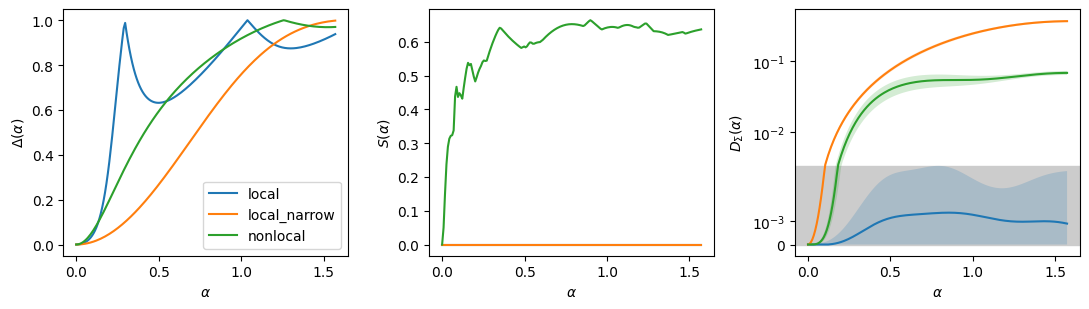

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for series in SERIES:
    axes[0].plot(ENCODING_ANGLES, shape_change[series], label=series)
    axes[1].plot(ENCODING_ANGLES, statistics[series]["nonseparable_weight"])
    values = statistics[series]["prior_distance"]
    half_width = 1.96 * statistics[series]["prior_distance_error"]
    axes[2].plot(ENCODING_ANGLES, values)
    axes[2].fill_between(
        ENCODING_ANGLES, np.maximum(0.0, values - half_width), values + half_width, alpha=0.2
    )
axes[2].axhspan(0.0, noise_ceiling, color="0.8", zorder=0)
axes[2].set_yscale("symlog", linthresh=noise_ceiling)
for ax, label in zip(axes, (r"$\Delta(\alpha)$", r"$S(\alpha)$", r"$D_\Sigma(\alpha)$")):
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(label)
axes[0].legend()
fig.tight_layout()
plt.show()

## Summary

With the paper settings, the local path keeps the query gate a product unitary, so both absorbable series have $S \equiv 0$ exactly. Under the Haar prior $D_\Sigma(\alpha)$ stays within the sampling null (case I), while the narrow prior moves $\Sigma(\alpha)$ about 110 times above the noise ceiling (case II). The nonlocal path reaches $S \approx 0.66$ and clears the null in $D_\Sigma$ (case III). The joint query spectrum is the same at every $\alpha$ on both paths, so none of these differences comes from new query frequencies. The naive shape change $\Delta(\alpha)$ approaches 1 for all three series and does not distinguish the cases.